# Canadian rental market, October 2025

An analysis of CMHC's *Rental Market Survey, Canada, 2025* across 43 cities: how expensive rent is, how fast it rose, and who is driving the increases.

**Key findings**
- Montréal's average 2-bedroom rent ($1,346) is below the Canadian average ($1,599) and well below Toronto and Vancouver, but its rent rose the most of the six big cities (+7.2%).
- Most of Montréal's increase came from tenants who stayed. In Toronto, Ottawa-Gatineau (Ont. part) and Vancouver, most of it came from new tenants.
- New tenants pay about 21% more than sitting tenants in Montréal and Toronto, but about 1% in Edmonton.
- Markets with lower vacancy tend to have bigger rent increases (correlation -0.4).

**Data:** CMHC, Rental Market Survey, Canada, 2025 (Oct 2024 and Oct 2025). Not included in this repo, see the README. Values CMHC hides appear as gaps, and its quality ratings (a-d) are not used.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_FILE = Path("../data/rmr-canada-2025-en.xlsx")
CHART_DIR = Path("../charts")
FOCUS_CITY = "Montréal"

CITY_COLORS = {
    "Montréal": "#d1495b",
    "Toronto": "#edae49",
    "Vancouver": "#00798c",
    "Calgary": "#30638e",
    "Edmonton": "#66a182",
    "Ottawa-Gatineau (Ont. part)": "#8d6cab",
}
OTHER_COLOR = "#c9c9c9"
BIG_CITIES = list(CITY_COLORS)

plt.rcParams.update({"figure.figsize": (9, 5), "axes.spines.top": False, "axes.spines.right": False})

def city_colors(names):
    return [CITY_COLORS.get(name, OTHER_COLOR) for name in names]

def save_and_show(name):
    CHART_DIR.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(CHART_DIR / f"{name}.png", dpi=150)
    plt.show()

## Data preparation
The CMHC sheets have title rows, two-row headers, quality letters next to each value, and numbers stored as text. `load_table` keeps the chosen columns (by position), converts text to numbers (hidden values become `NaN`), drops non-data rows, and flags cities versus provinces and Canada totals.

In [2]:
def load_table(sheet, columns):
    """columns = {position in the sheet: new name}. Position 0 must be the centre name."""
    raw = pd.read_excel(DATA_FILE, sheet_name=sheet, header=None)
    df = raw[list(columns)].rename(columns=columns).dropna(subset=["centre"]).copy()
    numeric = df.columns.drop("centre")
    df[numeric] = df[numeric].apply(lambda s: pd.to_numeric(s.astype(str).str.replace(",", ""), errors="coerce"))
    df = df.dropna(subset=numeric, how="all")
    df["centre"] = df["centre"].str.strip()
    df["is_city"] = ~df["centre"].str.contains(r"10,000\+|^Canada")
    df["centre"] = df["centre"].str.replace(r"\s+(CMA|CA)\b", "", regex=True)
    return df

# Table 1.0: vacancy, turnover, average 2-bedroom rent and its change
t1 = load_table("Table 1.0", {0: "centre", 1: "vacancy_2024", 3: "vacancy_2025",
                              6: "turnover_2024", 8: "turnover_2025",
                              11: "rent_2bed_2024", 13: "rent_2bed_2025",
                              15: "rent_change_to_2024", 17: "rent_change_2025"})

# Table 6.0: average rent for new tenants (turnover units) vs sitting tenants (non-turnover units)
BEDROOMS = ["studio", "1bed", "2bed", "3bed", "total"]
NEW_TENANT_POSITIONS = [4, 8, 12, 16, 20]
SAME_TENANT_POSITIONS = [26, 30, 34, 38, 42]
columns_60 = {0: "centre"}
columns_60.update(zip(NEW_TENANT_POSITIONS, [f"new_tenant_{b}" for b in BEDROOMS]))
columns_60.update(zip(SAME_TENANT_POSITIONS, [f"same_tenant_{b}" for b in BEDROOMS]))
t60 = load_table("Table 6.0", columns_60)

# Table 6.1: total rent change and the share coming from tenant turnover (percentage points)
t61 = load_table("Table 6.1", {0: "centre", 4: "all_units_change_2025", 8: "turnover_contribution_2025"})

The three tables are joined with a left join so that cities with values hidden by CMHC (such as Calgary's 2025 rent change) stay in the data as gaps. The new-tenant premium is `new tenant rent / sitting tenant rent - 1`.

In [3]:
cities = (t1[t1.is_city]
          .merge(t60.drop(columns="is_city"), on="centre", how="left")
          .merge(t61.drop(columns="is_city"), on="centre", how="left"))
cities["new_tenant_premium"] = (cities.new_tenant_total / cities.same_tenant_total - 1) * 100
national = t1[t1.centre == "Canada CMAs"].iloc[0]

print(len(cities), "cities")
cities[cities.centre.isin(BIG_CITIES)].set_index("centre")[["vacancy_2025", "rent_2bed_2025", "rent_change_2025", "new_tenant_premium"]].round(1)

43 cities


,vacancy_2025,rent_2bed_2025,rent_change_2025,new_tenant_premium
centre,,,,
Montréal,2.9,1346.0,7.2,21.3
Ottawa-Gatineau (Ont. part),3.0,1926.0,3.4,13.4
Toronto,3.0,2046.0,3.4,21.1
Calgary,5.0,1914.0,NaN,-2.3
Edmonton,3.8,1603.0,3.5,1.2
Vancouver,3.7,2363.0,2.2,19.0


## 1. Rent levels
Vancouver has the highest average 2-bedroom rent ($2,363), followed by Victoria, Kelowna and Toronto. Montréal ($1,346) is below the Canadian average and ranks 36th of 43 cities.

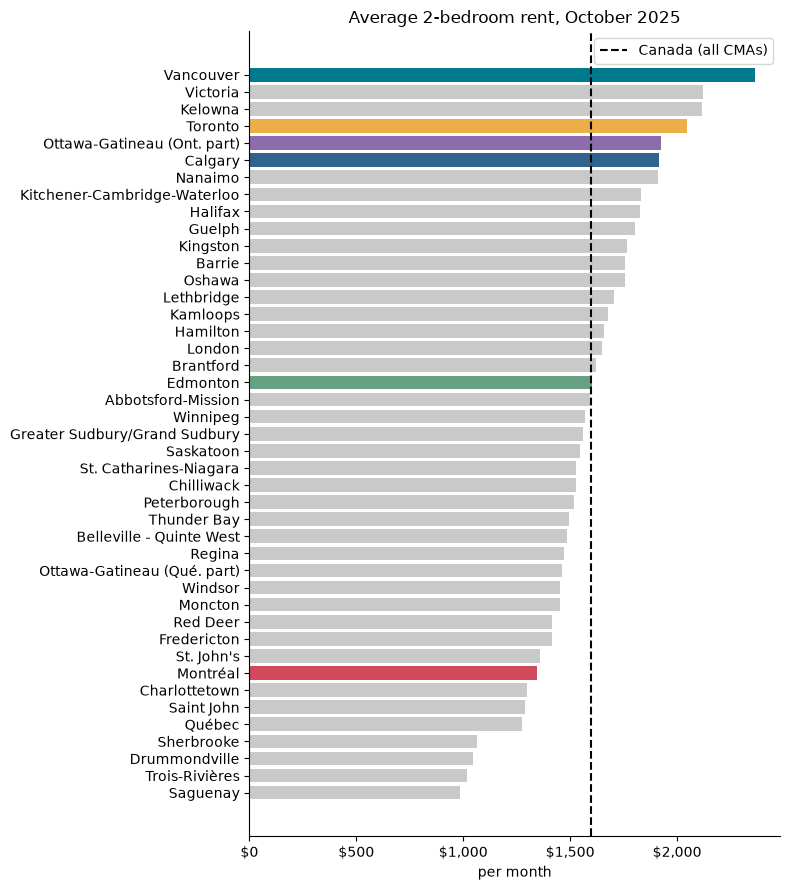

In [4]:
d = cities.dropna(subset=["rent_2bed_2025"]).sort_values("rent_2bed_2025")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(d.centre, d.rent_2bed_2025, color=city_colors(d.centre))
ax.axvline(national.rent_2bed_2025, color="black", ls="--", label="Canada (all CMAs)")
ax.set(title="Average 2-bedroom rent, October 2025", xlabel="per month")
ax.xaxis.set_major_formatter("${x:,.0f}")
ax.legend()
save_and_show("01_rent_level")

## 2. Rent growth
Rent in Montréal rose 7.2% between October 2024 and October 2025, against 5.0% for Canada overall, the 4th-largest increase among the 34 cities with data. Among the six big cities it is the largest; Vancouver's is the smallest (2.2%). Calgary's value is hidden by CMHC.

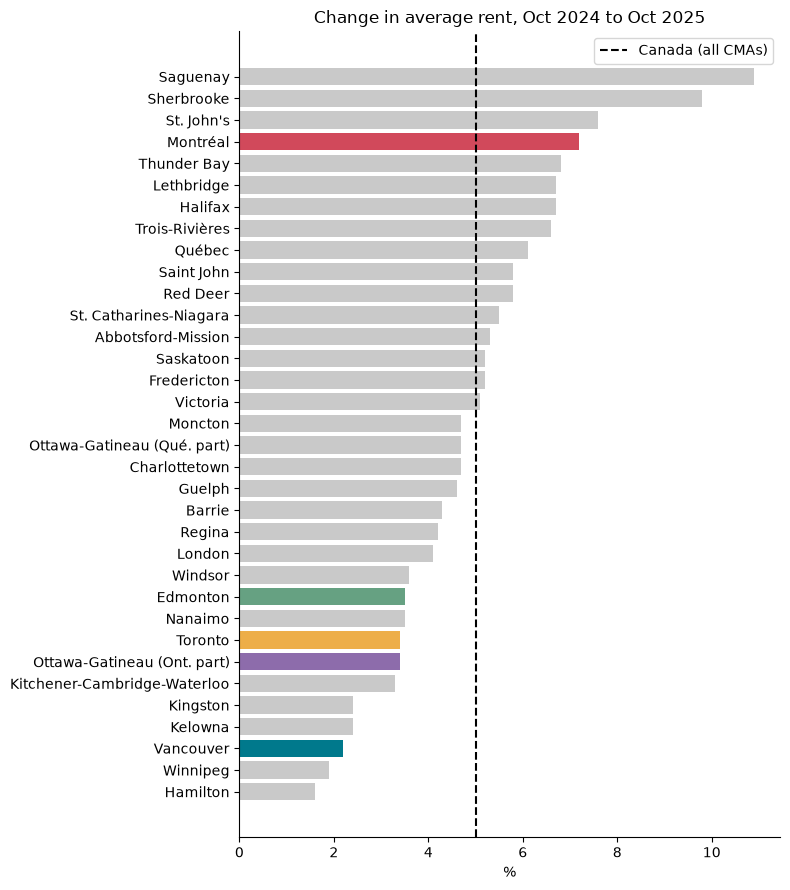

In [5]:
d = cities.dropna(subset=["rent_change_2025"]).sort_values("rent_change_2025")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(d.centre, d.rent_change_2025, color=city_colors(d.centre))
ax.axvline(national.rent_change_2025, color="black", ls="--", label="Canada (all CMAs)")
ax.set(title="Change in average rent, Oct 2024 to Oct 2025", xlabel="%")
ax.legend()
save_and_show("02_rent_change")

## 3. Vacancy and rent growth
Cities with lower vacancy tend to have larger rent increases, but the link is weak to moderate (correlation -0.4). This is a pattern across cities, not evidence of cause.

Correlation: -0.4


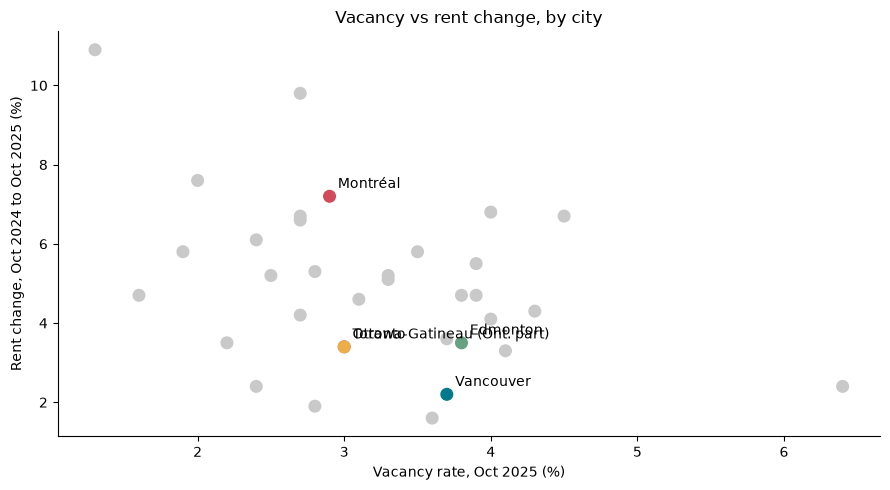

In [6]:
d = cities.dropna(subset=["vacancy_2025", "rent_change_2025"])
fig, ax = plt.subplots()
ax.scatter(d.vacancy_2025, d.rent_change_2025, color=city_colors(d.centre), s=70)
for _, row in d[d.centre.isin(BIG_CITIES)].iterrows():
    ax.annotate(row.centre, (row.vacancy_2025, row.rent_change_2025), xytext=(6, 6), textcoords="offset points")
ax.set(title="Vacancy vs rent change, by city", xlabel="Vacancy rate, Oct 2025 (%)", ylabel="Rent change, Oct 2024 to Oct 2025 (%)")
print("Correlation:", round(d.vacancy_2025.corr(d.rent_change_2025), 2))
save_and_show("03_vacancy_vs_change")

## 4. Steady vs volatile cities
Comparing each city's rent increase in two consecutive years, Moncton, Fredericton, Barrie and Nanaimo changed the least (under 0.6 points). Toronto is also among the five steadiest, at a moderate level of increase.

Steadiest cities (smallest swing, in points):
     centre  swing
    Moncton    0.1
Fredericton    0.3
     Barrie    0.4
    Nanaimo    0.5
    Toronto    0.7


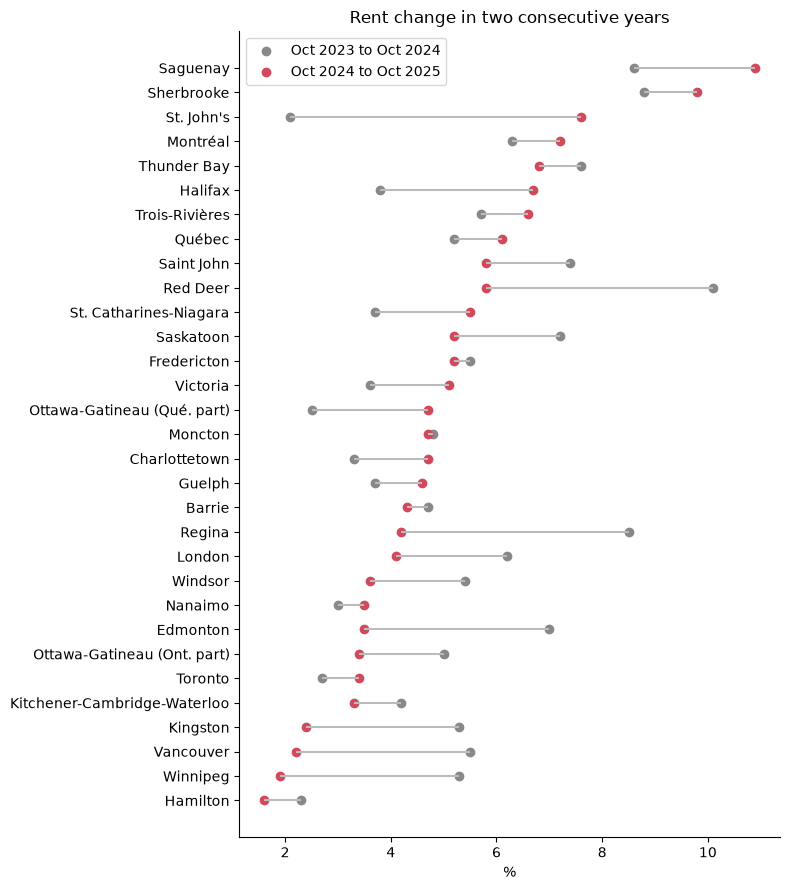

In [7]:
d = cities.dropna(subset=["rent_change_to_2024", "rent_change_2025"]).copy()
d["swing"] = (d.rent_change_2025 - d.rent_change_to_2024).abs()
d = d.sort_values("rent_change_2025")
fig, ax = plt.subplots(figsize=(8, 9))
ax.hlines(d.centre, d.rent_change_to_2024, d.rent_change_2025, color="#bbbbbb")
ax.scatter(d.rent_change_to_2024, d.centre, color="#888888", label="Oct 2023 to Oct 2024")
ax.scatter(d.rent_change_2025, d.centre, color="#d1495b", label="Oct 2024 to Oct 2025")
ax.set(title="Rent change in two consecutive years", xlabel="%")
ax.legend()
print("Steadiest cities (smallest swing, in points):")
print(d.sort_values("swing")[["centre", "swing"]].head(5).round(1).to_string(index=False))
save_and_show("04_steady_vs_swing")

## 5. New-tenant premium
New tenants pay about 21% more than sitting tenants in Montréal and Toronto and 19% in Vancouver, against 13% in Ottawa-Gatineau (Ont. part) and about 1% in Edmonton.

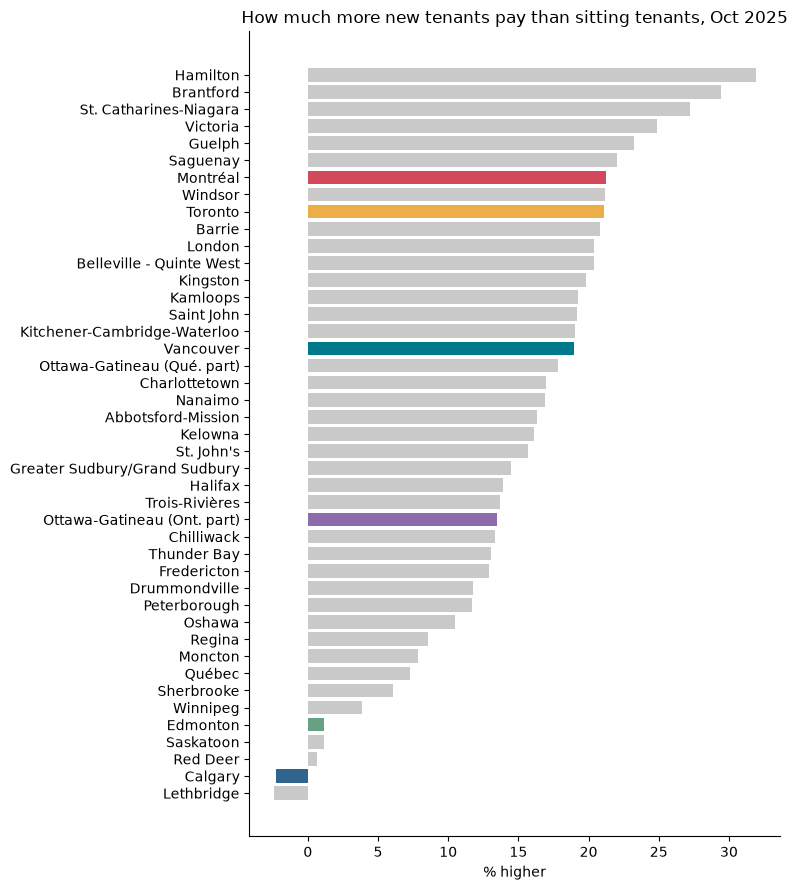

In [8]:
d = cities.dropna(subset=["new_tenant_premium"]).sort_values("new_tenant_premium")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(d.centre, d.new_tenant_premium, color=city_colors(d.centre))
ax.set(title="How much more new tenants pay than sitting tenants, Oct 2025", xlabel="% higher")
save_and_show("05_new_tenant_premium")

## 6. Rent by bedroom count (Montréal)
Set `FOCUS_CITY` at the top to change the city.

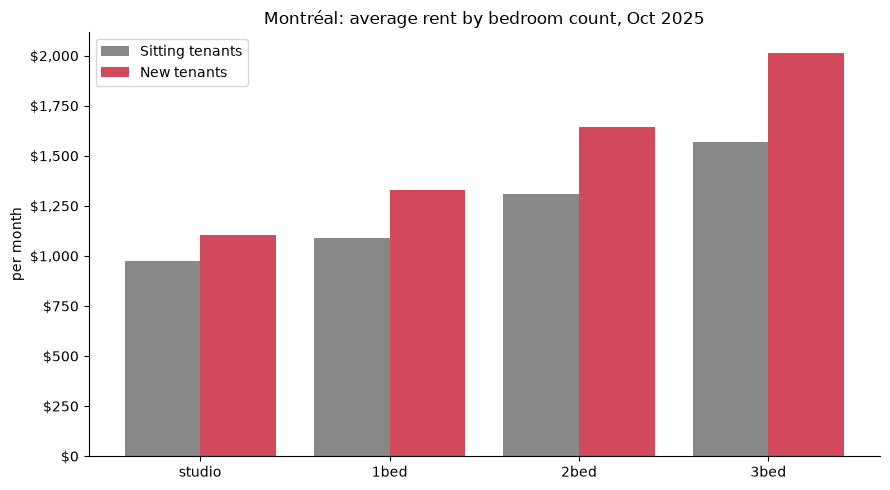

In [9]:
row = cities[cities.centre == FOCUS_CITY].iloc[0]
bedroom_types = BEDROOMS[:-1]
same = [row[f"same_tenant_{b}"] for b in bedroom_types]
new = [row[f"new_tenant_{b}"] for b in bedroom_types]
positions = range(len(bedroom_types))
bar_width = 0.4
fig, ax = plt.subplots()
ax.bar([p - bar_width / 2 for p in positions], same, bar_width, label="Sitting tenants", color="#888888")
ax.bar([p + bar_width / 2 for p in positions], new, bar_width, label="New tenants", color=CITY_COLORS.get(FOCUS_CITY, "#d1495b"))
ax.set_xticks(list(positions), bedroom_types)
ax.set(title=f"{FOCUS_CITY}: average rent by bedroom count, Oct 2025", ylabel="per month")
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.legend()
save_and_show("06_focus_city_bedrooms")

## 7. Sources of the rent increase
Montréal's 7.2% increase is mostly from sitting tenants (5.5 points), with 1.7 points from new tenants. Toronto (2.4 of 3.4), Ottawa-Gatineau (2.2 of 3.4) and Vancouver (2.0 of 2.2) show the opposite: most of the increase is from turnover. Calgary is not shown because CMHC hides its values.

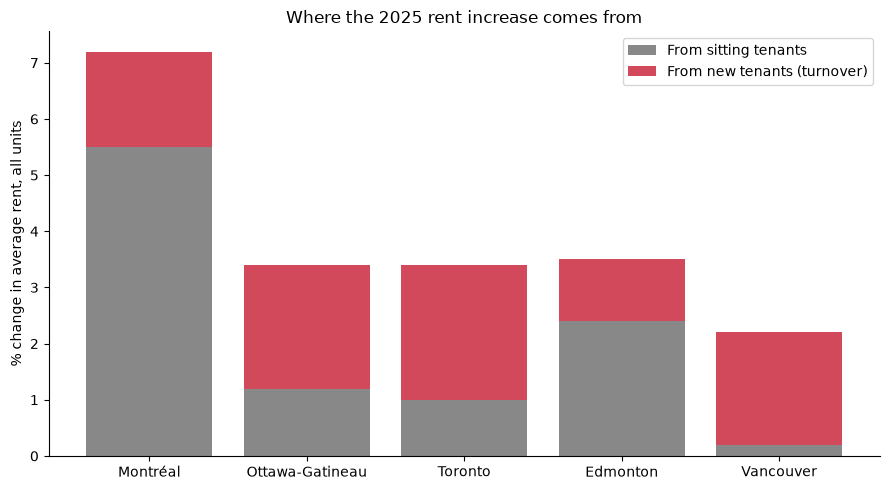

In [10]:
d = cities[cities.centre.isin(BIG_CITIES)].dropna(subset=["all_units_change_2025", "turnover_contribution_2025"])
labels = d.centre.str.replace(r" \(.*\)", "", regex=True)
from_sitting = d.all_units_change_2025 - d.turnover_contribution_2025
fig, ax = plt.subplots()
ax.bar(labels, from_sitting, color="#888888", label="From sitting tenants")
ax.bar(labels, d.turnover_contribution_2025, bottom=from_sitting, color="#d1495b", label="From new tenants (turnover)")
ax.set(title="Where the 2025 rent increase comes from", ylabel="% change in average rent, all units")
ax.legend()
save_and_show("07_turnover_contribution")

## Source and notes
- Canada Mortgage and Housing Corporation (CMHC), *Rental Market Survey, Canada, 2025*. All rights belong to CMHC.
- Turnover units are apartments that got a new tenant in the past year; non-turnover units kept the same tenant.
- Code drafted with Claude (Anthropic) via Claude Code.